# Part 10: Model Selection {-}

In [1]:
import warnings
warnings.filterwarnings(action='ignore')
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

To this point, we have considered estimating parameters using maximum likelihood after a particular model has been **assumed**.

It makes sense to extend this idea to comparing different candidate models. As long as the data being fit remains exactly the same, likelihood values can be compared. 

If we only seek to maximize the likelihood over candidate models, we will be led
to **overfitting** to the sample, since a model with more complexity (more parameters, more flexibility), will necessarily fit better to the data.

\newpage

## Example: Alternatives to the Lognormal Pricing Model {-}

Here, let $S_t$ denote the closing price of some equity on day $t$.

Some theoretical results (e.g., Black-Scholes) assume the **lognormal pricing model**, in which $S_t = S_{t-1} X_t$, where $X_t$ has the lognormal$(\mu,\sigma^2)$
distribution, i.e., that $\log(X_t)$ has the Normal$(\mu,\sigma^2)$ distribution.
It is further assumed that $X_1, X_2, \ldots$ are independent. 

This model is known to not fit well to real data. In particular, log returns have heavier
tails than the normal distribution.

Consider the returns for Proctor & Gamble (PG) from 2015 to 2025:

In [2]:
PGdat = yf.Ticker("PG").history(start="2015-01-01",end="2025-12-31")
ldrPG = np.log(PGdat['Close']).diff()[1:]

\newpage

The normal probability plot below makes clear the deficiencies in the normal assumption.

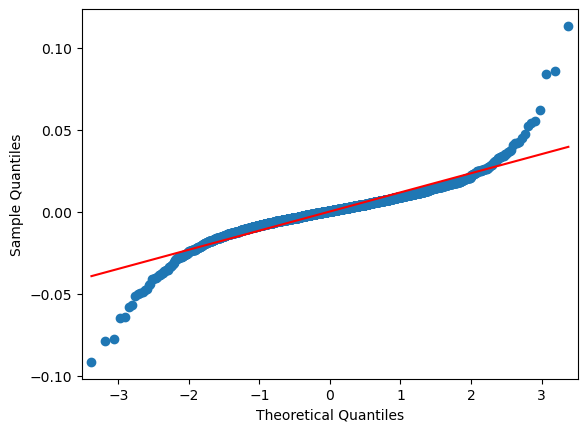

In [3]:
from statsmodels.graphics.gofplots import qqplot
import scipy.stats.distributions as spdists
import matplotlib.pyplot as plt

qqplot(ldrPG,line="s")
plt.show()

\newpage

Another way to highlight the problem with the normal fit is to compare
the **kernel density estimate (KDE)** with the best-fitting
normal distribution. The KDE is a **nonparametric** approach to estimating a density, meaning that it does not make any assumptions regarding the form of the density.

Note how the log scale is used to emphasize the problems in the tails.

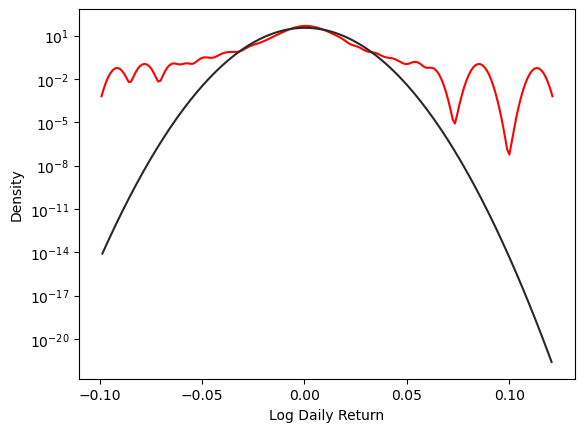

In [4]:
import seaborn as sns
from scipy.stats import norm
import matplotlib.pyplot as plt

ax = sns.distplot(ldrPG, hist=False, kde_kws={"bw": "silverman"}, color="red", fit=norm)
plt.xlabel("Log Daily Return")
plt.ylabel("Density")
plt.yscale("log")
plt.show()

The deficiencies in the normal distribution have led people to
consider alternatives. Here we will look at a few and then
compare their fit to our return data.

\newpage

## The Generalized Error Distribution (GED) {-}

(This is sometimes referred to as the **generalized normal distribution**.)

Random variable $X$ has the GED with mean $\mu$, scale
$\alpha$, and shape $\beta$ if
\begin{equation*}
   f_X(x) = \frac{\beta}{2\alpha \Gamma(1/\beta)}
   \exp\left[\left(-\frac{|x-\mu|}{\alpha}\right)^{\beta}\right]
   , \:\:\: -\infty < x< \infty, \:\:\beta >0, \:\:\alpha >0
\end{equation*}


**Comments:**

1. When $\beta=2$, this is the normal$(\mu, \alpha^2/2)$ distribution. When $\beta=1$, this is
the **double exponential** or **Laplace** distribution.

2. The distributions are symmetric around $\mu$.

3. Package `scipy.stats` includes `gennorm`.

\newpage

**Exercise:** Use the code below to explore the effect of varying $\beta$ on the shape of the pdf of this distribution.

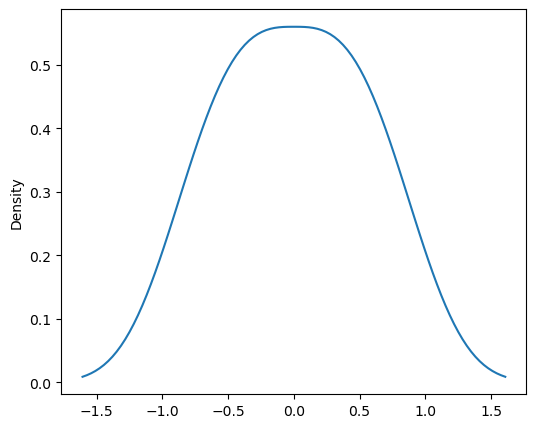

In [5]:
from scipy.stats import gennorm

beta = 3
x = np.linspace(gennorm.ppf(0.001, beta), gennorm.ppf(0.999, beta), 100)
plt.figure(figsize=[6,5])
plt.plot(x, gennorm.pdf(x, beta))
plt.ylabel("Density")
plt.show()

\newpage

## The Nonstandard $t$-distribution {-}

Assume $T$ has the (standard) $t$-distribution with $\nu$ degrees of
freedom. Then define
\begin{equation}
   X = \mu + \sigma T
\end{equation}
where $\sigma > 0$.

This distribution with have the "shape" of the $t$-distribution, but
will have mean $\mu$ and scale $\sigma$. We will call this the **nonstandard t-distribution**.

In Python, this distribution is implemented via `scipy.stats.t`.

**Exercise:** What is the variance of a random variable with this distribution?

\answerlines{5}

\newpage

## Skewed t-Distribution {-}

Jones and Faddy introduced a *skewed* generalization of the t-distribution, allowing for asymmetry. ("A Skew Extension of the t-Distribution, with Applications," _JRSSB_, 2003.)

The skew is captured by a pair of positive parameters, which they denote $a$ and $b$. If $a<b$, then the distribution is negatively skewed; if $a>b$, the distribution is positively skewed; and if $a=b$ the distribution is equivalent to the nonstandard $t$-distribution with $2a$ degrees of freedom.

The Jones and Faddy paper provides some properties of the distribution, including that
\begin{equation*}
E(T) = \mu + \frac{(a-b) \sqrt{a+b} \:\Gamma\!\left(a-\frac{1}{2}\right) \Gamma\!\left(b-\frac{1}{2}\right)}{2\Gamma(a)\Gamma(b)}.
\end{equation*}

\newpage

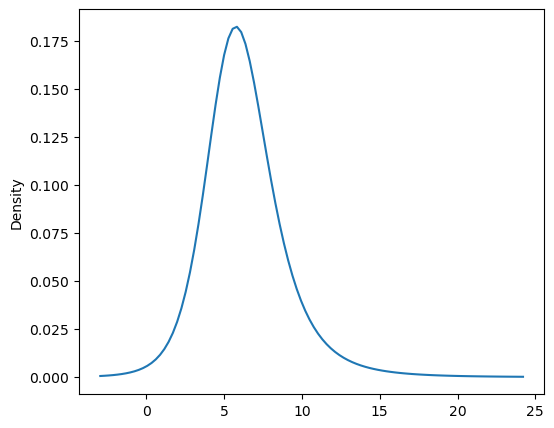

In [6]:
from scipy.stats import jf_skew_t,t

a = 3
b = 2
mu = 5
scl = 2

x = np.linspace(jf_skew_t.ppf(0.001, a,b,mu,scl), jf_skew_t.ppf(0.999, a,b,mu,scl), 100)

plt.figure(figsize=[6,5])
plt.plot(x, jf_skew_t.pdf(x, a,b,mu,scl))
plt.ylabel("Density")
plt.show()

\newpage

## Fitting the Models {-}

We will use maximum likelihood to fit all of the proposed models to the PG
data. The following Python functions make this easy. We will start by scaling the returns, since the original values are sufficiently small to create numerical problems.

In [7]:
ldrPGscl = ldrPG * 100

In [8]:
normalfit = norm.fit(ldrPGscl)
GEDfit = gennorm.fit(ldrPGscl)
tfit = t.fit(ldrPGscl)
skewTfit = jf_skew_t.fit(ldrPGscl)

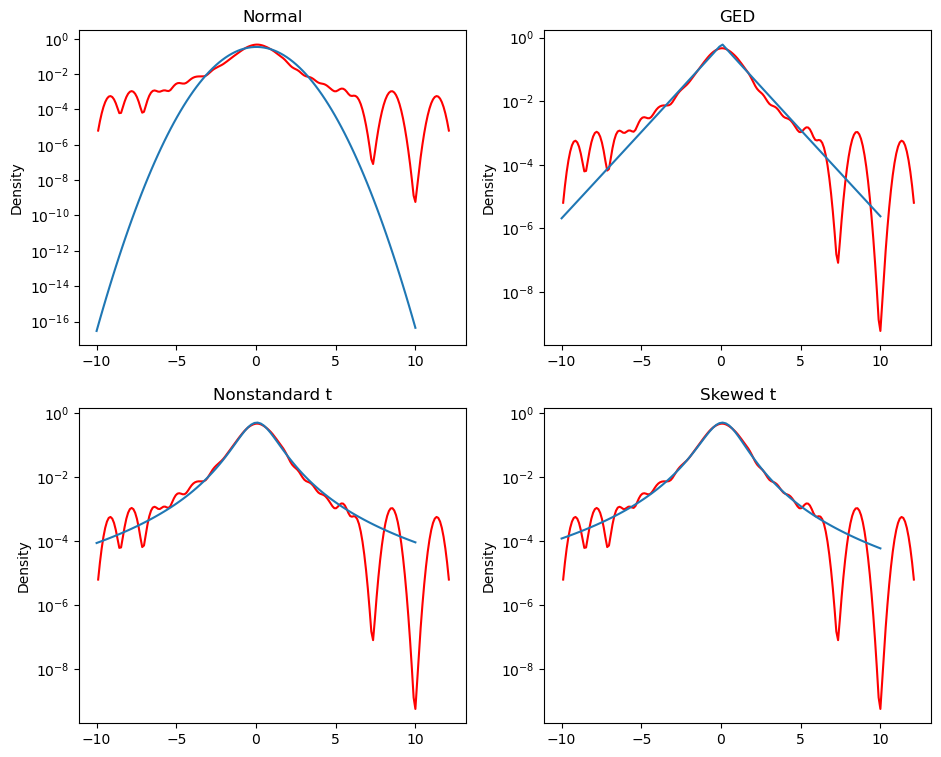

In [9]:
fig = plt.figure(figsize=(11, 9))

x = np.linspace(-10,10,100)

# Normal

ax = fig.add_subplot(2, 2, 1)
    
sns.distplot(ldrPGscl, hist=False, kde_kws={"bw_method": "silverman"}, color="red", ax=ax)

plt.plot(x,norm.pdf(x,*normalfit))
plt.yscale("log")
plt.xlabel("")
plt.title("Normal")

# GED

ax = fig.add_subplot(2, 2, 2)
    
sns.distplot(ldrPGscl, hist=False, kde_kws={"bw_method": "silverman"}, color="red", ax=ax)

plt.plot(x,gennorm.pdf(x,*GEDfit))
plt.yscale("log")
plt.xlabel("")
plt.title("GED")

# Nonstandard t

ax = fig.add_subplot(2, 2, 3)
    
sns.distplot(ldrPGscl, hist=False, kde_kws={"bw_method": "silverman"}, color="red", ax=ax)

plt.plot(x,t.pdf(x,*tfit))
plt.yscale("log")
plt.xlabel("")
plt.title("Nonstandard t")

# Skewed t

ax = fig.add_subplot(2, 2, 4)
    
sns.distplot(ldrPGscl, hist=False, kde_kws={"bw_method": "silverman"}, color="red", ax=ax)

plt.plot(x,jf_skew_t.pdf(x,*skewTfit))

plt.yscale("log")
plt.xlabel("")
plt.title("Skewed t")

plt.show()

\newpage

Calculate the log likelihood for each of the four models:

In [10]:
print(f"Normal:   {sum(norm.logpdf(ldrPGscl,*normalfit)):6.2f}")
print(f"GED:      {sum(gennorm.logpdf(ldrPGscl,*GEDfit)):6.2f}")
print(f"Nonstd T: {sum(t.logpdf(ldrPGscl,*tfit)):6.2f}")
print(f"Skewed T: {sum(jf_skew_t.logpdf(ldrPGscl,*skewTfit)):6.2f}")

Normal:   -4346.11
GED:      -4023.61
Nonstd T: -3982.99
Skewed T: -3980.38


**Exercise:** Should these four models be ranked using their
likelihoods?

\answerlines{8}

\newpage

## Overfitting {-}

Model 1 is **nested** in Model 2 if Model 1 is
a special case of Model 2. In this case, the likelihood maximized under
Model 2 will necessarily be greater than or equal to the likelihood
maximized under Model 1.

In our example, Normal is nested in the GED and the nonstandard $t$ distribution
is nested in the skewed $t$ distribution.

**But:** Increased likelihood may not be a sign of a better fitting model. It is
possible that we are simply **overfitting** to the available sample.

Our objective is to fit well to the **population**, not just to
the observed sample. The sample may contain **artifacts** which
appear to be real features, but would disappear with a larger sample size.

\newpage

**Example:** Suppose that a sample of size $n=50$ is drawn from the Uniform$(0,1)$
distribution. If we inspect the histogram of this sample, it is not going to be
"flat" due to natural variability.

We may be tempted to fit a Beta$(\alpha, \beta)$ distribution to this sample, in 
an effort to fit to any "features" we observe. This would be a mistake, and would
be overfitting.

See the figure below. Maximum likelihod is used to fit the Beta
distribution to the uniform data.

**Exercise:** Label the "artifacts" in this histogram.

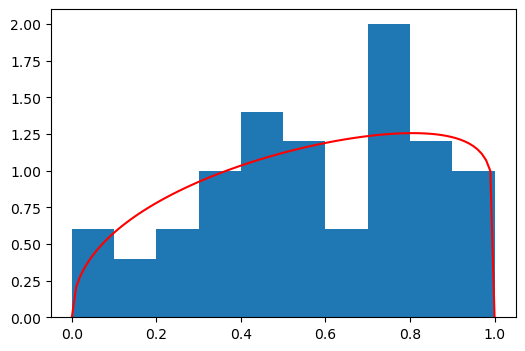

In [11]:
from scipy.stats import uniform, beta
import random

n = 50

random.seed(0)

x = uniform.rvs(size=n,random_state=6)

xbar = np.mean(x)
V = np.var(x)

alphahat = xbar*(xbar*(1-xbar)/V - 1)
betahat = (1-xbar)*alphahat/xbar

plt.figure(figsize=(6, 4))
xseq = np.linspace(0,1,100)
plt.hist(x,density=True,bins=np.linspace(0,1,11))

plt.plot(xseq,beta.pdf(xseq,alphahat,betahat),color="red")
plt.show()

\newpage

Models with more parameters have greater flexibility to fit to features, but also
artifacts, in observed data. Hence, the risk of overfitting increases greatly as
we consider models with a larger number of parameters (and more complexity).

We have previously discussed using AIC in the context of linear regression, but
the concept is more general. The general definition of AIC is as follows:
\begin{equation*}
  {\rm AIC} = -2 \log L(\theta) + 2p
\end{equation*}
where $p$ is the number of parameters in the model. Recall that we seek the model that has the
smallest value of AIC.

We think of $2p$ as being a "penalty" on the likelihood for the complexity of the model.

**Exercise:** Which of our four candidate models is selected by AIC in the PG example?

In [12]:
print(f"Normal:   {-2*sum(norm.logpdf(ldrPGscl,*normalfit))+4:6.2f}")
print(f"GED:      {-2*sum(gennorm.logpdf(ldrPGscl,*GEDfit))+6:6.2f}")
print(f"Nonstd T: {-2*sum(t.logpdf(ldrPGscl,*tfit))+6:6.2f}")
print(f"Skewed T: {-2*sum(jf_skew_t.logpdf(ldrPGscl,*skewTfit))+8:6.2f}")

Normal:   8696.22
GED:      8053.22
Nonstd T: 7971.97
Skewed T: 7968.75


\newpage

The figures below highlight the similarity, but significant difference in the tail, when comparing the nonstandard $t$ and the skewed $t$ fits.

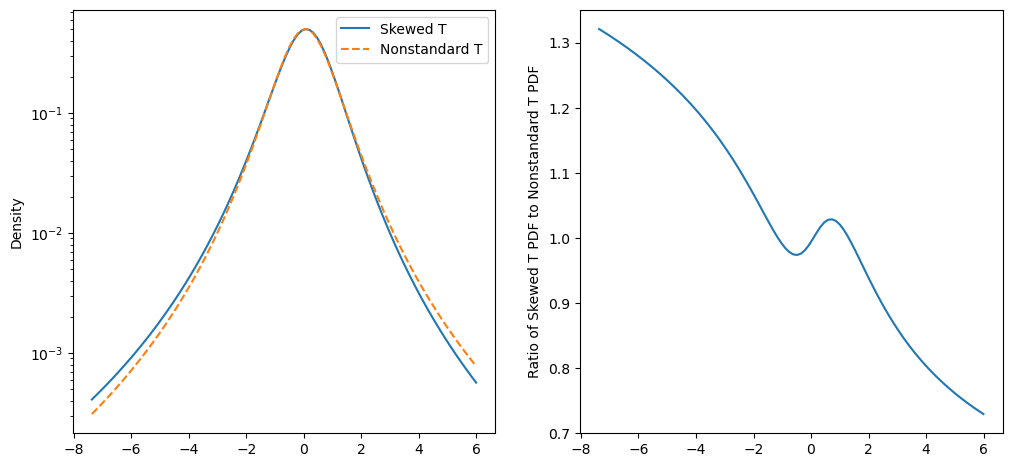

In [13]:
x = np.linspace(jf_skew_t.ppf(0.001, *skewTfit), jf_skew_t.ppf(0.999, *skewTfit), 100)

fig = plt.figure(figsize=(12, 5.5))

fig.add_subplot(1, 2, 1)
plt.plot(x, jf_skew_t.pdf(x, *skewTfit),label="Skewed T")
plt.plot(x,t.pdf(x,*tfit),label="Nonstandard T",linestyle="--")
plt.yscale("log")
plt.ylabel("Density")
plt.legend()

fig.add_subplot(1, 2, 2)
plt.plot(x, jf_skew_t.pdf(x, *skewTfit)/t.pdf(x,*tfit))
plt.ylabel("Ratio of Skewed T PDF to Nonstandard T PDF")
plt.show()

\newpage

**Exercise:** In a previous Part we considered the fitting of the GARCH(1,1) model to daily log returns. Now consider the more general GARCH$(p,q)$ model, and also consider the possibility that a distribution other than the normal would be the best choice for the $\epsilon_t$.

More specifically, our model takes the following form: The observation at time $t$ is
\begin{equation*}
   X_t = \mu + \sigma_t \epsilon_t
\end{equation*}
where
\begin{equation*}
   \sigma_t^2 = \omega + \sum_{i=1}^p \alpha_i X_{t-i}^2 + \sum_{j=1}^q \beta_j \sigma_{t-j}^2
\end{equation*}
and $\epsilon_t$ are iid with mean zero, variance one, and a specified distribution (e.g., normal, GED, etc.).

Note that we are now also allowing the overall mean $\mu$ to be nonzero.

What choice does AIC make among all of these possible models?

Does AIC find that including the mean $\mu$ in the model is worthwhile?

\answerlines{8}

In [14]:
from arch import arch_model

maxp = 3
maxq = 3
errdists = ('normal','ged','t','skewt')

print("p q Dist     AIC")
print("------------------")
for dist in errdists:
    for p in range(maxp):
        if(p==0):
            holdaic = arch_model(ldrPGscl, mean="Constant", vol="Constant", dist=dist).fit(disp="off",update_freq=0).aic
            print(f"iid {dist:6s} {holdaic:6.2f}")
        else:
            for q in range(maxq):
                holdaic = arch_model(ldrPGscl,mean='Constant',p=p,q=q,vol="GARCH",dist=dist).fit(disp="off",update_freq=0).aic
                print(f"{p:1d} {q:1d} {dist:6s} {holdaic:6.2f}")         

p q Dist     AIC
------------------
iid normal 8696.22
1 0 normal 8292.29
1 1 normal 8078.12
1 2 normal 8079.82
2 0 normal 8160.78
2 1 normal 8080.12
2 2 normal 8081.19
iid ged    8053.54
1 0 ged    7914.72
1 1 ged    7792.28
1 2 ged    7794.05
2 0 ged    7855.85
2 1 ged    7794.28
2 2 ged    7795.27
iid t      7971.97
1 0 t      7870.82
1 1 t      7745.24
1 2 t      7747.03
2 0 t      7821.52
2 1 t      7747.24
2 2 t      7748.22
iid skewt  7969.68
1 0 skewt  7869.16
1 1 skewt  7737.47
1 2 skewt  7739.38
2 0 skewt  7817.57
2 1 skewt  7739.47
2 2 skewt  7740.80


In [15]:
arch_model(ldrPGscl, mean="zero", vol="Garch", p=1,q=1,dist="skewt").fit(disp="off",update_freq=0).aic

7739.247234540975